# 06 — Real-event plane versus curved fronts

**Question:** Does a quadratic front explain measured timing structure, and does its
advantage persist in conditional held-out predictions and a fixed development sample?

This is an **Auger-core-assisted** analysis. We use the released selected stations
and reconstructed core, never the official direction or shower-plane distances
as optimizer inputs. Agreement with Auger is not accuracy against known truth.

Run with the project Python kernel: **Restart Kernel → Run All**. Saved output does
not restore variables in a new kernel. Every complete run gets its own output
directory. No station rejection, timing-uncertainty rescaling, core tuning against
the reference direction, or protected-test fitting is performed.

Read [the frozen protocol](../docs/real_front_comparison_protocol.md) first.
Notebook 03 remains our unchanged plane-only baseline; Notebook 05 contains the
known-truth controls, not measured-event results.


**Coordinate-frame update (2026-10-14).** Reference comparisons now rotate Auger's core-local ENU direction into the central-site ENU frame used by the station coordinates and fitted vectors. No station coordinates or fit objectives are changed. Superseded comparison outputs have been cleared; restart the kernel and run all cells for a new, fully versioned run. Historical result directories remain unchanged. See `docs/conference_coordinate_audit.md`.


## 1. Freeze settings and provenance

We reuse the tested fitters. A plane has three fitted parameters; a quadratic front
with a **fixed** core has four. Their nominal residual degrees of freedom are
$N-3$ and $N-4$. Those denominators do not guarantee an exact chi-square law,
especially at zero curvature or with inherited reconstruction inputs.

Source hashes, library versions, the event-selection manifest, and all numerical
options are saved. If source files change during a run, restart instead of mixing
different implementations.


In [1]:
import json
import shutil
import subprocess
from dataclasses import asdict
from datetime import UTC, datetime
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path
from platform import python_version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from auger_reco.data import core_reference, development_sample, direction_reference, event_json
from auger_reco.evaluation import front_comparison
from auger_reco.physics import curved_front, plane_front, quadratic_front

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "auger_reco").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook inside the Auger project.")
    ROOT = ROOT.parent

FOCUS_ID = "081847956000"
MANIFEST_PATH = ROOT / "data/manifests/real_front_development_v1.json"
NOTEBOOK_PATH = ROOT / "notebooks/06_compare_real_event_front_models.ipynb"
PROTOCOL_PATH = ROOT / "docs/real_front_comparison_protocol.md"
PLANE_OPTIONS = plane_front.PlaneFrontFitOptions(minimum_stations=6)
CURVED_OPTIONS = curved_front.QuadraticFrontFitOptions(minimum_stations=6)
FIXED_CORE_SHIFT_M = 100.0
MODULES = (
    core_reference,
    development_sample,
    direction_reference,
    event_json,
    front_comparison,
    plane_front,
    curved_front,
    quadratic_front,
)
SOURCE_PATHS = {module.__name__: Path(module.__file__).resolve() for module in MODULES}
if any(not path.is_relative_to(ROOT / "src") for path in SOURCE_PATHS.values()):
    raise RuntimeError("A module came from a different project installation.")
SOURCE_HASHES = {name: sha256(path.read_bytes()).hexdigest() for name, path in SOURCE_PATHS.items()}


def require_state(*names):
    missing = [name for name in names if name not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing}. Restart Kernel and Run All; saved output is not state."
        )


def json_safe(value):
    """Represent unavailable/nonfinite diagnostics as null, never nonstandard NaN."""
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def write_json(path, value):
    path.write_text(
        json.dumps(json_safe(value), indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )


def verify_sources():
    for name, path in SOURCE_PATHS.items():
        if sha256(path.read_bytes()).hexdigest() != SOURCE_HASHES[name]:
            raise RuntimeError(f"{name} changed. Restart Kernel and Run All.")


manifest_bytes = MANIFEST_PATH.read_bytes()
manifest = json.loads(manifest_bytes)
run_tag = datetime.now(UTC).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = ROOT / "reports/results" / f"real_front_comparison_{run_tag}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / "sources").mkdir()
for name, path in SOURCE_PATHS.items():
    shutil.copy2(path, RUN_DIR / "sources" / f"{name}.py")
shutil.copy2(NOTEBOOK_PATH, RUN_DIR / "notebook_at_run_start.ipynb")
shutil.copy2(PROTOCOL_PATH, RUN_DIR / PROTOCOL_PATH.name)
(RUN_DIR / "selection_manifest.json").write_bytes(manifest_bytes)
configuration = {
    "created_utc": datetime.now(UTC).isoformat(),
    "focus_event": FOCUS_ID,
    "plane_options": asdict(PLANE_OPTIONS),
    "quadratic_options": asdict(CURVED_OPTIONS),
    "fixed_core_shift_m": FIXED_CORE_SHIFT_M,
    "source_sha256": SOURCE_HASHES,
    "direction_frame_version": direction_reference.DIRECTION_FRAME_VERSION,
    "selection_manifest_sha256": sha256(manifest_bytes).hexdigest(),
    "python": python_version(),
    "packages": {name: version(name) for name in ("numpy", "scipy", "pandas", "matplotlib", "pyproj")},
    "git_head": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "git_status": subprocess.check_output(["git", "status", "--short"], cwd=ROOT, text=True),
    "role": "core-assisted, inherited station selection, training-only development",
    "held_out_caveat": "fixed full-event Auger core and selection; not end-to-end cross-validation",
    "nonfinite_json": "unavailable or nonfinite numeric diagnostics serialized as null",
}
write_json(RUN_DIR / "configuration.json", configuration)
write_json(RUN_DIR / "run_status.json", {"state": "running"})
print(f"Outputs: {RUN_DIR}")

Outputs: /home/abdul_samad/projects/auger-direction-reconstruction/reports/results/real_front_comparison_20261010T201113_597655Z


## 2. Validate the preselected development sample

The sample contains the previously examined focus event and 19 additional
training events, chosen deterministically before their reconstruction results
were inspected. The seven-station eligibility requirement supports six-station
leave-one-out fits and restricts the population to which these results apply.

Downloads happen separately through the bounded official-source downloader.
Missing files are reported, not replaced by more favourable events. No test or
validation event is admitted. The original pilot is not changed.


In [2]:
require_state("manifest", "RUN_DIR")
sample_rows = manifest["events"]
sample_ids = [str(row["event_id"]).zfill(12) for row in sample_rows]
if len(sample_ids) != 20 or len(set(sample_ids)) != 20 or sample_ids[0] != FOCUS_ID:
    raise ValueError("Expected the frozen focus event plus 19 unique development events.")
if any(row["split"] != "train" for row in sample_rows[1:]):
    raise ValueError("A protected event entered the development sample.")
# Read only identity/split/count/bins, never protected reference-angle columns.
pilot_path = ROOT / "data/manifests/pilot_sd1500_vertical_v1.csv"
if manifest["status"] != "frozen_before_download_and_fit":
    raise ValueError("The development manifest is not frozen.")
if sha256(pilot_path.read_bytes()).hexdigest() != manifest["source_sha256"]:
    raise ValueError("The pilot manifest differs from the selection source.")
safe_pilot = development_sample.load_selection_rows(pilot_path)
regenerated = development_sample.select_development_events(safe_pilot)
if [row["event_id"] for row in regenerated] != sample_ids[1:]:
    raise ValueError("Frozen selection does not reproduce from the declared rule.")
pilot_splits = {str(row["event_id"]).zfill(12): row["split"] for row in safe_pilot}
if any(pilot_splits.get(event_id) != "train" for event_id in sample_ids[1:]):
    raise ValueError("Development manifest no longer agrees with the frozen pilot split.")
event_paths = {
    event_id: ROOT / "data/raw/events" / f"Auger_{event_id}.json" for event_id in sample_ids
}
initial_event_hashes = {
    event_id: sha256(path.read_bytes()).hexdigest()
    for event_id, path in event_paths.items()
    if path.is_file()
}
write_json(RUN_DIR / "input_file_sha256.json", initial_event_hashes)
display(pd.DataFrame(sample_rows))
print(f"Available files: {len(initial_event_hashes)}/{len(sample_ids)}")

,event_id,role,split,selected_stations,zenith_bin,multiplicity_bin
0,081847956000,focus_previously_unblinded,previously_examined_focus,NaN,NaN,NaN
1,160210414600,training_development,train,13.0,0-15,12+
2,120797883000,training_development,train,7.0,0-15,6-7
3,130207988600,training_development,train,8.0,0-15,8-11
4,140876912800,training_development,train,12.0,15-30,12+
5,133556408900,training_development,train,7.0,15-30,6-7
6,112954615400,training_development,train,8.0,15-30,8-11
7,123274772200,training_development,train,12.0,30-45,12+
8,113434887000,training_development,train,7.0,30-45,6-7
9,163051054600,training_development,train,8.0,30-45,8-11


Available files: 20/20


## 3. Define the experiment without the reference direction

For $\mathbf d_i=\mathbf r_i-\mathbf r_{\rm core}$ and downward unit propagation
vector $\mathbf u$, the curved timing model is

$$t_i^{\rm pred}=t_{\rm core}+\frac{\mathbf d_i\cdot\mathbf u}{c}
 + A\frac{\|\mathbf d_i\times\mathbf u\|^2}{(1000\,{\rm m})^2},\qquad A\ge0.$$

$A$ is the quadratic delay at 1 km perpendicular distance. Direction, time, and
$A$ are fitted; the core is fixed. The plane comparator is the $A=0$ timing family.
No official radius, direction, or axis-distance field is supplied to the solver.

Core shifts include $\pm100$ m along x/y and, when provided, $\pm dx$ and $\pm dy$.
They are separate sensitivity probes, not a confidence ellipse: covariance is
not available. The released local z coordinate is preserved, not replaced by
absolute altitude.

The leave-one-out routine removes the omitted time from fitting. It retains the
Auger core and original selection, so its predictions are **conditional**, not
a leakage-free reconstruction of the entire event.


In [3]:
def core_probes(core):
    offsets = [
        (FIXED_CORE_SHIFT_M, 0.0, 0.0),
        (-FIXED_CORE_SHIFT_M, 0.0, 0.0),
        (0.0, FIXED_CORE_SHIFT_M, 0.0),
        (0.0, -FIXED_CORE_SHIFT_M, 0.0),
    ]
    labels = ["fixed_x_plus_100m", "fixed_x_minus_100m", "fixed_y_plus_100m", "fixed_y_minus_100m"]
    for axis, uncertainty in enumerate((core.uncertainty_x_m, core.uncertainty_y_m)):
        if uncertainty is not None:
            for sign, word in ((1.0, "plus"), (-1.0, "minus")):
                vector = np.zeros(3)
                vector[axis] = sign * uncertainty
                offsets.append(tuple(vector))
                labels.append(f"released_{'xy'[axis]}_{word}_axis_uncertainty")
    return np.array(offsets, dtype=float), labels


def run_event(event_id):
    verify_sources()
    path = event_paths[event_id]
    if event_id not in initial_event_hashes:
        raise FileNotFoundError(f"Preselected event unavailable: {path}")
    if sha256(path.read_bytes()).hexdigest() != initial_event_hashes[event_id]:
        raise RuntimeError("Event changed during the run.")
    measured = event_json.load_auger_plane_front_input(
        path, selection=event_json.StationSelection.OFFICIAL_SELECTED, minimum_stations=7
    )
    core = core_reference.load_auger_core_reference(path)
    if measured.canonical_event_id != event_id:
        raise ValueError("Requested and embedded event IDs differ.")
    if (core.event_id, core.embedded_release, core.format_version) != (
        measured.event_id,
        measured.embedded_release,
        measured.format_version,
    ):
        raise ValueError("Core and timing metadata differ.")
    offsets, labels = core_probes(core)
    result = front_comparison.compare_event_fronts(
        measured.station_positions_m,
        measured.observed_times_ns,
        measured.timing_uncertainties_ns,
        core.position_m,
        station_ids=measured.station_ids,
        plane_options=PLANE_OPTIONS,
        curved_options=CURVED_OPTIONS,
        core_offsets_m=offsets,
        run_leave_one_out=True,
    )
    directory = RUN_DIR / event_id
    directory.mkdir(exist_ok=False)
    stations = pd.DataFrame(
        {
            "station_id": measured.station_ids,
            "x_m": measured.station_positions_m[:, 0],
            "y_m": measured.station_positions_m[:, 1],
            "z_m": measured.station_positions_m[:, 2],
            "observed_time_ns": measured.observed_times_ns,
            "uncertainty_ns": measured.timing_uncertainties_ns,
        }
    )
    stations.to_csv(directory / "input_stations.csv", index=False)
    write_json(directory / "core_input.json", asdict(core))
    write_json(directory / "configuration.json", result.configuration)
    write_json(directory / "fit_records.json", result.records)
    write_json(directory / "optimizer_attempts.json", result.optimizer_attempts)
    pd.DataFrame(result.records).to_csv(directory / "fit_records.csv", index=False)
    pd.DataFrame(result.station_residuals).to_csv(directory / "station_residuals.csv", index=False)
    pd.DataFrame(
        {
            "scenario": [f"core_shift_{index}" for index in range(len(labels))],
            "probe_label": labels,
            "offset_x_m": offsets[:, 0],
            "offset_y_m": offsets[:, 1],
        }
    ).to_csv(directory / "core_probe_labels.csv", index=False)
    write_json(
        directory / "input_metadata.json",
        {
            "event_id": event_id,
            "embedded_release": measured.embedded_release,
            "format_version": measured.format_version,
            "selected_stations": measured.number_of_stations,
            "triggered_stations": measured.triggered_station_count,
            "selection_policy": measured.selection_policy.value,
            "adapter_flags": measured.quality_flags,
            "event_sha256": initial_event_hashes[event_id],
        },
    )
    return measured, core, result


event_runs = {}
event_outcomes = []
for event_id in sample_ids:
    try:
        event_runs[event_id] = run_event(event_id)
    except (OSError, ValueError, RuntimeError, FloatingPointError, np.linalg.LinAlgError) as error:
        event_outcomes.append(
            {
                "event_id": event_id,
                "loaded_and_compared": False,
                "failure_type": type(error).__name__,
                "failure_message": str(error),
            }
        )
        print(f"{event_id}: retained failure — {type(error).__name__}: {error}")
    else:
        comparison_result = event_runs[event_id][2]
        successes = sum(bool(row["success"]) for row in comparison_result.records)
        event_outcomes.append(
            {
                "event_id": event_id,
                "loaded_and_compared": True,
                "fit_attempts": len(comparison_result.records),
                "fit_successes": successes,
            }
        )
        print(f"{event_id}: {successes}/{len(comparison_result.records)} fits succeeded")
    write_json(RUN_DIR / "event_outcomes.json", event_outcomes)

# No official direction has been loaded by this notebook at this point.
if FOCUS_ID not in event_runs:
    raise RuntimeError("Focus event failed; inspect event_outcomes.json before interpreting.")
full_records = []
station_records = []
for event_id, (_, _, result) in event_runs.items():
    full_records.extend({"event_id": event_id, **row} for row in result.records)
    station_records.extend({"event_id": event_id, **row} for row in result.station_residuals)
records = pd.DataFrame(full_records)
station_columns = [
    "event_id",
    "fit_id",
    "stage",
    "model",
    "weighting",
    "scenario",
    "station_id",
    "station_index",
    "observed_time_ns",
    "predicted_time_ns",
    "residual_ns",
    "timing_uncertainty_ns",
    "residual_over_observed_sigma",
    "axis_distance_m",
    "residual_kind",
]
station_results = pd.DataFrame(station_records).reindex(columns=station_columns)
numeric_metrics = [
    "zenith_deg",
    "azimuth_deg",
    "delay_at_1km_ns",
    "chi_square",
    "reduced_chi_square",
    "rms_residual_ns",
    "sky_x",
    "sky_y",
    "sky_z",
    "direction_shift_from_full_deg",
]
for name in numeric_metrics:
    records[name] = pd.to_numeric(records[name], errors="raise")
records.to_csv(RUN_DIR / "all_fit_records_before_reference.csv", index=False)
station_results.to_csv(RUN_DIR / "all_station_residuals.csv", index=False)
if records["nested_objective_violation"].fillna(False).any():
    raise RuntimeError("Nested objective check failed; preserve this run for investigation.")
print("All model predictions have been saved before reference-direction evaluation.")

081847956000: 108/108 fits succeeded


160210414600: 64/64 fits succeeded


120797883000: 40/40 fits succeeded


130207988600: 44/44 fits succeeded


140876912800: 60/60 fits succeeded


133556408900: 40/40 fits succeeded


... (10 outputs left out)

103648222300: 68/68 fits succeeded


162706023800: 40/40 fits succeeded


133323550000: 44/44 fits succeeded


080523660200: 68/68 fits succeeded
All model predictions have been saved before reference-direction evaluation.


## 4. Compare saved predictions with the published direction

Only now do we load Auger's sky-arrival direction and rotate its core-local ENU
vector into the central-site ENU basis used by our fits,
and calculate the angle between two vectors. This is **separation from a
reconstructed reference**, not an error against known truth.

The focus event was already unblinded. For every event, the inherited core and
selection also share information with the official reconstruction. A closer
direction is useful descriptive evidence, not an independent accuracy proof.


In [ ]:
require_state("event_runs", "records")
comparison = records.copy()
comparison["fit_direction_frame"] = "central-site WGS84 geodetic ENU"
comparison["direction_frame_version"] = direction_reference.DIRECTION_FRAME_VERSION
comparison["separation_from_auger_deg"] = np.nan
references = []
for event_id, (measured, _, _) in event_runs.items():
    path = event_paths[event_id]
    if sha256(path.read_bytes()).hexdigest() != initial_event_hashes[event_id]:
        raise RuntimeError("Event changed before reference evaluation.")
    site_reference = direction_reference.load_auger_site_direction_reference(path)
    reference = site_reference.reference
    if (reference.event_id, reference.embedded_release, reference.format_version) != (
        measured.event_id,
        measured.embedded_release,
        measured.format_version,
    ):
        raise ValueError("Reference and fitted-event metadata differ.")
    reference_sky = site_reference.sky_direction_site
    write_json(RUN_DIR / event_id / "direction_frame_metadata.json", site_reference.frame_metadata)
    indices = comparison.index[(comparison["event_id"] == event_id) & comparison["success"]]
    comparison.loc[indices, "separation_from_auger_deg"] = [
        plane_front.angular_separation_deg(
            comparison.loc[index, ["sky_x", "sky_y", "sky_z"]].to_numpy(dtype=float),
            reference_sky,
        )
        for index in indices
    ]
    references.append(
        {
            "event_id": event_id,
            "auger_core_zenith_deg": reference.zenith_deg,
            "auger_core_azimuth_deg": reference.azimuth_deg,
            "reference_sky_site_x": reference_sky[0],
            "reference_sky_site_y": reference_sky[1],
            "reference_sky_site_z": reference_sky[2],
            "direction_frame_version": direction_reference.DIRECTION_FRAME_VERSION,
        }
    )
comparison.to_csv(RUN_DIR / "comparison_with_auger.csv", index=False)
pd.DataFrame(references).to_csv(RUN_DIR / "evaluation_references.csv", index=False)
full = comparison.loc[comparison["stage"] == "full"].copy()
focus_full = full.loc[full["event_id"] == FOCUS_ID]
display(
    focus_full[
        [
            "model",
            "weighting",
            "success",
            "zenith_deg",
            "azimuth_deg",
            "delay_at_1km_ns",
            "reduced_chi_square",
            "rms_residual_ns",
            "separation_from_auger_deg",
            "quality_flags",
        ]
    ]
)

## 5. Conditional held-out timing and core sensitivity

Each omitted station is predicted from an $N-1$ timing fit. We summarize
$\sqrt{\mathrm{mean}(e_{\rm heldout}^2)}$ and
$\mathrm{mean}[(e_{\rm heldout}/dt)^2]$. The latter is **not reduced chi-square**:
we do not subtract fitted parameters from the number of held-out observations.
It is also not a calibrated predictive pull because fit uncertainty is absent.

Compare models on the **same successful station folds**. Failures are counted
separately; a method must not appear better by losing its difficult folds.
The core remains fixed from the original full-event Auger reconstruction.


In [ ]:
require_state("station_results", "comparison")
held = station_results.loc[station_results["residual_kind"] == "held_out"].copy()
loo_attempts = comparison.loc[comparison["stage"] == "leave_one_out"].copy()
heldout_rows = []
paired_heldout_rows = []
for event_id, (measured, _, _) in event_runs.items():
    for weighting in ("timing", "uniform"):
        subset = held.loc[(held["event_id"] == event_id) & (held["weighting"] == weighting)]
        pivot = subset.pivot(index="station_id", columns="model", values="residual_ns")
        scaled = subset.pivot(
            index="station_id", columns="model", values="residual_over_observed_sigma"
        )
        for model in ("plane", "quadratic"):
            values = subset.loc[subset["model"] == model]
            attempts = loo_attempts.loc[
                (loo_attempts["event_id"] == event_id)
                & (loo_attempts["weighting"] == weighting)
                & (loo_attempts["model"] == model)
            ]
            heldout_rows.append(
                {
                    "event_id": event_id,
                    "weighting": weighting,
                    "model": model,
                    "expected_folds": measured.number_of_stations,
                    "successful_folds": len(values),
                    "failed_folds": int((~attempts["success"]).sum()),
                    "heldout_rms_ns": float(np.sqrt(np.mean(values["residual_ns"] ** 2)))
                    if len(values)
                    else np.nan,
                    "heldout_mean_squared_normalized_error": float(
                        np.mean(values["residual_over_observed_sigma"] ** 2)
                    )
                    if len(values)
                    else np.nan,
                }
            )
        common = pivot.reindex(columns=["plane", "quadratic"]).dropna()
        common_scaled = scaled.reindex(index=common.index, columns=["plane", "quadratic"])
        paired_heldout_rows.append(
            {
                "event_id": event_id,
                "weighting": weighting,
                "expected_folds": measured.number_of_stations,
                "complete_pairs": len(common),
                "plane_rms_ns": float(np.sqrt(np.mean(common["plane"] ** 2)))
                if len(common)
                else np.nan,
                "quadratic_rms_ns": float(np.sqrt(np.mean(common["quadratic"] ** 2)))
                if len(common)
                else np.nan,
                "plane_normalized_mse": float(np.mean(common_scaled["plane"] ** 2))
                if len(common)
                else np.nan,
                "quadratic_normalized_mse": float(np.mean(common_scaled["quadratic"] ** 2))
                if len(common)
                else np.nan,
            }
        )
heldout_summary = pd.DataFrame(heldout_rows)
paired_heldout = pd.DataFrame(paired_heldout_rows)
heldout_summary.to_csv(RUN_DIR / "heldout_summary.csv", index=False)
paired_heldout.to_csv(RUN_DIR / "paired_heldout_summary.csv", index=False)
display(heldout_summary.loc[heldout_summary["event_id"] == FOCUS_ID])
focus_shifts = comparison.loc[
    (comparison["event_id"] == FOCUS_ID) & (comparison["stage"] == "core_shift")
].merge(pd.read_csv(RUN_DIR / FOCUS_ID / "core_probe_labels.csv"), on="scenario")
display(
    focus_shifts[
        [
            "probe_label",
            "success",
            "direction_shift_from_full_deg",
            "reduced_chi_square",
            "delay_at_1km_ns",
            "separation_from_auger_deg",
        ]
    ]
)

## 6. Inspect the focus event visually

Both residual plots use identical selected stations and the same horizontal
distance from the published core. That plotting distance contains no reference
direction. The fitter still uses the perpendicular distance to its **own**
candidate axis. The vertical residual scale and colour limits are shared across
models so a visual improvement cannot come from independently scaled axes.

The held-out figure shows the omitted-station errors rather than in-sample
residuals. Core-shift plots report changes from the nominal curved fit, not an
optimization of reference agreement.


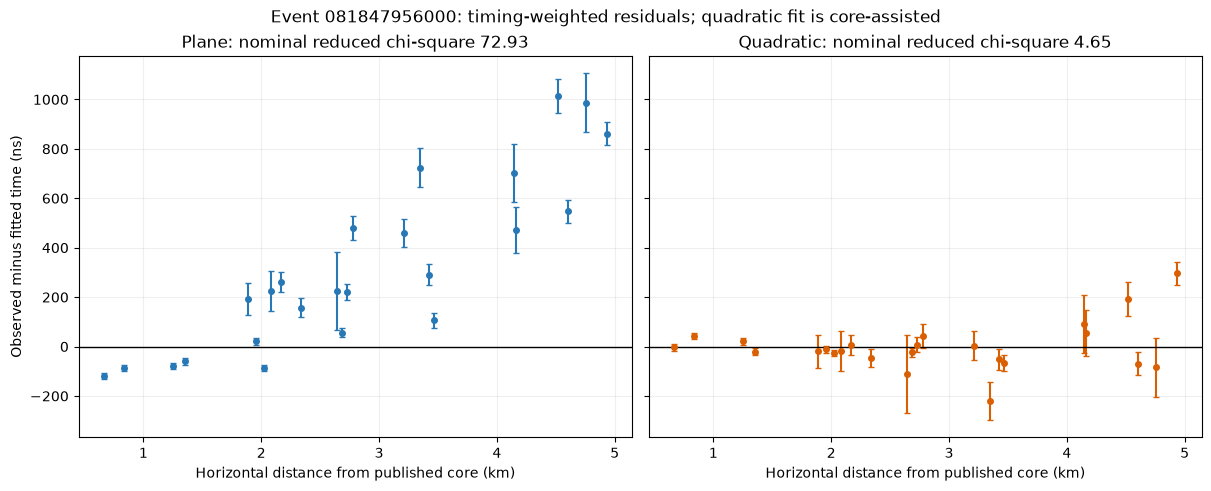

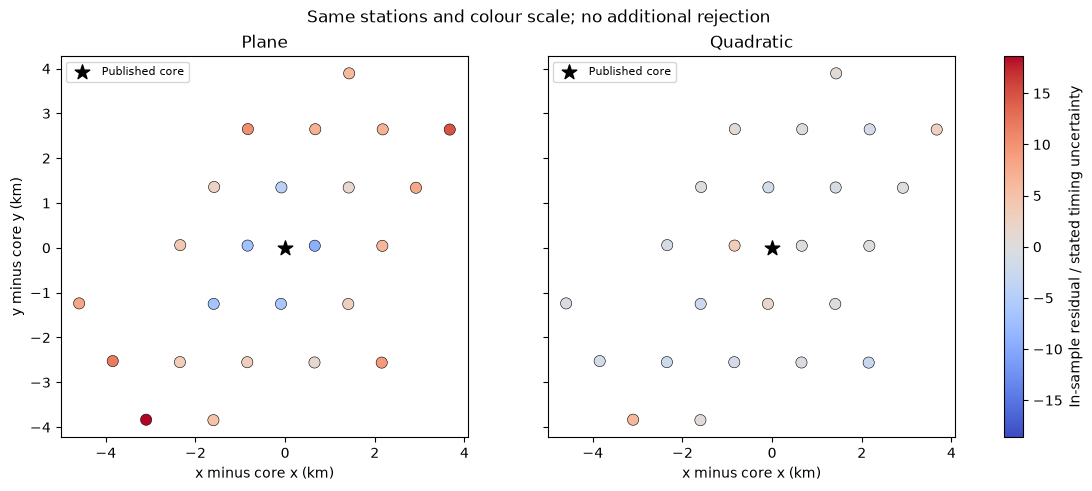

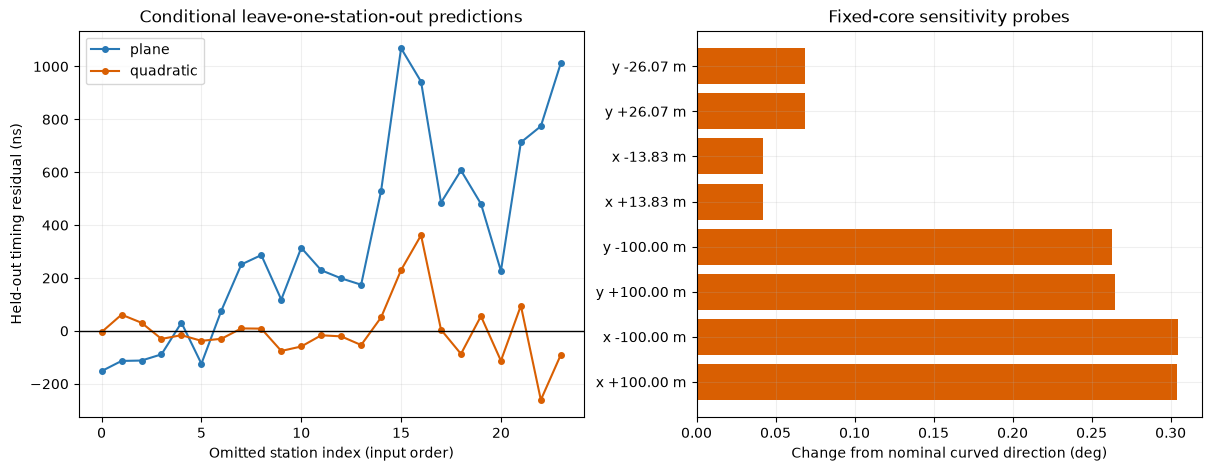

In [6]:
require_state("focus_full", "focus_shifts", "held")
measured, core, focus_result = event_runs[FOCUS_ID]
required_focus_fits = {(model, "timing") for model in ("plane", "quadratic")}
if not required_focus_fits.issubset(focus_result.full_fits):
    display(
        Markdown(
            "Focus comparison plots unavailable: a required full fit failed. "
            "See fit_records.csv; no result has been substituted."
        )
    )
else:
    positions = measured.station_positions_m
    horizontal_distance = np.linalg.norm(positions[:, :2] - core.position_m[:2], axis=1)
    focus_fits = {
        model: focus_result.full_fits[(model, "timing")] for model in ("plane", "quadratic")
    }
    colors = {"plane": "#2878b5", "quadratic": "#d95f02"}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
    for ax, (model, fitted) in zip(axes, focus_fits.items(), strict=True):
        ax.errorbar(
            horizontal_distance / 1000,
            fitted.residuals_ns,
            yerr=measured.timing_uncertainties_ns,
            fmt="o",
            ms=4,
            color=colors[model],
            capsize=2,
        )
        ax.axhline(0, color="black", lw=1)
        ax.set(
            title=(
                f"{model.capitalize()}: nominal reduced chi-square {fitted.reduced_chi_square:.2f}"
            ),
            xlabel="Horizontal distance from published core (km)",
        )
        ax.grid(alpha=0.2)
    axes[0].set_ylabel("Observed minus fitted time (ns)")
    fig.suptitle(f"Event {FOCUS_ID}: timing-weighted residuals; quadratic fit is core-assisted")
    fig.savefig(RUN_DIR / "focus_residuals_vs_distance.png", dpi=200)
    plt.show()

    limit = max(float(np.max(np.abs(f.standardized_residuals))) for f in focus_fits.values())
    fig, axes = plt.subplots(
        1, 2, figsize=(11, 4.8), sharex=True, sharey=True, layout="constrained"
    )
    for ax, (model, fitted) in zip(axes, focus_fits.items(), strict=True):
        scatter = ax.scatter(
            (positions[:, 0] - core.position_m[0]) / 1000,
            (positions[:, 1] - core.position_m[1]) / 1000,
            c=fitted.standardized_residuals,
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit,
            s=65,
            edgecolors="black",
            linewidths=0.4,
        )
        ax.scatter(0, 0, marker="*", c="black", s=120, label="Published core")
        ax.set(title=model.capitalize(), xlabel="x minus core x (km)", aspect="equal")
        ax.legend(loc="best", fontsize=8)
    axes[0].set_ylabel("y minus core y (km)")
    fig.colorbar(scatter, ax=axes, label="In-sample residual / stated timing uncertainty")
    fig.suptitle("Same stations and colour scale; no additional rejection")
    fig.savefig(RUN_DIR / "focus_residual_maps.png", dpi=200)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
    focus_held = held.loc[(held["event_id"] == FOCUS_ID) & (held["weighting"] == "timing")]
    for model in ("plane", "quadratic"):
        values = focus_held.loc[focus_held["model"] == model].sort_values("station_index")
        axes[0].plot(
            values["station_index"],
            values["residual_ns"],
            "o-",
            label=model,
            color=colors[model],
            ms=4,
        )
    axes[0].axhline(0, color="black", lw=1)
    axes[0].set(
        xlabel="Omitted station index (input order)",
        ylabel="Held-out timing residual (ns)",
        title="Conditional leave-one-station-out predictions",
    )
    axes[0].legend()
    successful_shifts = focus_shifts.loc[focus_shifts["success"]]
    axes[1].barh(
        [
            f"x {row.offset_x_m:+.2f} m" if row.offset_x_m != 0 else f"y {row.offset_y_m:+.2f} m"
            for row in successful_shifts.itertuples(index=False)
        ],
        successful_shifts["direction_shift_from_full_deg"],
        color=colors["quadratic"],
    )
    axes[1].set(
        xlabel="Change from nominal curved direction (deg)", title="Fixed-core sensitivity probes"
    )
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.savefig(RUN_DIR / "focus_heldout_and_core_sensitivity.png", dpi=200)
    plt.show()

## 7. Report every preselected development event

The previously examined focus event is excluded from the aggregate below.
The unit of aggregation is an **event**, not a station or an optimizer attempt.
Paired comparisons require successful fits from both models, and denominators
remain explicit. The sample is small, stratified and restricted to at least seven
selected stations; these are descriptive development results, not population
accuracy or protected-test performance.

For timing-weighted fits, we report reduced chi-square, conditional held-out
prediction, and reference separation as different measurements. They need not
improve together.


In [ ]:
require_state("full", "paired_heldout")
new_ids = sample_ids[1:]
development = full.loc[full["event_id"].isin(new_ids)]
metric_names = [
    "reduced_chi_square",
    "rms_residual_ns",
    "separation_from_auger_deg",
    "delay_at_1km_ns",
]
development_summary = development.groupby(["model", "weighting"]).agg(
    attempts=("success", "size"),
    successful_fits=("success", "sum"),
)
for metric in metric_names:
    development_summary[f"finite_count_{metric}"] = (
        development.loc[development["success"]].groupby(["model", "weighting"])[metric].count()
    )
    development_summary[f"median_{metric}"] = (
        development.loc[development["success"]].groupby(["model", "weighting"])[metric].median()
    )
development_summary["preselected_events"] = len(new_ids)
development_summary["direction_frame_version"] = direction_reference.DIRECTION_FRAME_VERSION
development_summary.to_csv(RUN_DIR / "development_method_summary.csv")
display(development_summary)

paired_event_rows = []
for event_id in new_ids:
    for weighting in ("timing", "uniform"):
        pair = development.loc[
            (development["event_id"] == event_id)
            & (development["weighting"] == weighting)
            & development["success"]
        ].set_index("model")
        complete = {"plane", "quadratic"}.issubset(pair.index)
        row = {"event_id": event_id, "weighting": weighting, "complete_pair": complete}
        for metric in ("reduced_chi_square", "rms_residual_ns", "separation_from_auger_deg"):
            for prefix in ("plane", "quadratic", "plane_minus_quadratic"):
                row[f"{prefix}_{metric}"] = np.nan
        if complete:
            for metric in ("reduced_chi_square", "rms_residual_ns", "separation_from_auger_deg"):
                row[f"plane_{metric}"] = pair.loc["plane", metric]
                row[f"quadratic_{metric}"] = pair.loc["quadratic", metric]
                row[f"plane_minus_quadratic_{metric}"] = (
                    pair.loc["plane", metric] - pair.loc["quadratic", metric]
                )
        paired_event_rows.append(row)
paired_events = pd.DataFrame(paired_event_rows)
paired_events["direction_frame_version"] = direction_reference.DIRECTION_FRAME_VERSION
paired_events.to_csv(RUN_DIR / "paired_development_events.csv", index=False)
display(paired_events)


def paired_scatter(ax, frame, x_column, y_column, label, log=False):
    valid = frame[[x_column, y_column]].dropna()
    if log:
        valid = valid.loc[(valid[x_column] > 0) & (valid[y_column] > 0)]
    if valid.empty:
        ax.text(0.5, 0.5, "No valid paired results", ha="center", transform=ax.transAxes)
        return
    ax.scatter(valid[x_column], valid[y_column], color="#39796b", edgecolors="black", s=40)
    lower = min(valid.min())
    upper = max(valid.max())
    if log:
        lower, upper = lower / 1.25, upper * 1.25
        ax.set_xscale("log")
        ax.set_yscale("log")
    else:
        lower, upper = 0.0, max(upper * 1.1, 1e-6)
    ax.plot([lower, upper], [lower, upper], "--", color="gray")
    ax.set(
        xlim=(lower, upper),
        ylim=(lower, upper),
        xlabel=f"Plane: {label}",
        ylabel=f"Core-assisted quadratic: {label}",
    )
    ax.grid(alpha=0.2)
    ax.set_title(f"{len(valid)}/{len(new_ids)} paired development events")


weighted_pairs = paired_events.loc[paired_events["weighting"] == "timing"]
dev_heldout = paired_heldout.loc[
    paired_heldout["event_id"].isin(new_ids) & (paired_heldout["weighting"] == "timing")
]
# A complete-event plot does not reward methods for failed omitted-station folds.
dev_heldout_complete = dev_heldout.loc[
    dev_heldout["complete_pairs"] == dev_heldout["expected_folds"]
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
paired_scatter(
    axes[0],
    weighted_pairs,
    "plane_reduced_chi_square",
    "quadratic_reduced_chi_square",
    "nominal reduced chi-square",
    log=True,
)
paired_scatter(
    axes[1],
    dev_heldout_complete,
    "plane_normalized_mse",
    "quadratic_normalized_mse",
    "conditional held-out normalized MSE",
    log=True,
)
paired_scatter(
    axes[2],
    weighted_pairs,
    "plane_separation_from_auger_deg",
    "quadratic_separation_from_auger_deg",
    "separation from Auger (deg)",
)
fig.suptitle("Timing-weighted development comparison — below diagonal favours quadratic")
fig.savefig(RUN_DIR / "development_paired_comparison.png", dpi=200)
plt.show()

## 8. Save an evidence-based conclusion and verify run integrity

This cell records what the run actually found, including failures. It does not
require the curved model to win, force chi-square toward one, or call reference
agreement truth recovery. The next scientific gate is to understand remaining
mismatch and core dependence before freezing a larger-cohort procedure.


In [ ]:
require_state("paired_events", "heldout_summary")
verify_sources()
if MANIFEST_PATH.read_bytes() != manifest_bytes:
    raise RuntimeError("Selection manifest changed during execution.")
for event_id, digest in initial_event_hashes.items():
    if sha256(event_paths[event_id].read_bytes()).hexdigest() != digest:
        raise RuntimeError(f"Input event {event_id} changed during execution.")

weighted_focus = focus_full.set_index(["model", "weighting"])
focus_table = [
    "| Model | Nominal reduced chi-square | RMS residual (ns) | Separation from Auger (deg) |",
    "|---|---:|---:|---:|",
]
for model in ("plane", "quadratic"):
    row = weighted_focus.loc[(model, "timing")]
    focus_table.append(
        f"| {model} | {row['reduced_chi_square']:.4f} | "
        f"{row['rms_residual_ns']:.3f} | {row['separation_from_auger_deg']:.6f} |"
    )
complete_pairs = weighted_pairs.loc[weighted_pairs["complete_pair"]]
closer = int((complete_pairs["plane_minus_quadratic_separation_from_auger_deg"] > 0).sum())
chi_pairs = complete_pairs.dropna(
    subset=["plane_reduced_chi_square", "quadratic_reduced_chi_square"]
)
lower_chi = int((chi_pairs["plane_minus_quadratic_reduced_chi_square"] > 0).sum())
better_heldout = int(
    (
        dev_heldout_complete["quadratic_normalized_mse"]
        < dev_heldout_complete["plane_normalized_mse"]
    ).sum()
)
failed_events = sum(not row["loaded_and_compared"] for row in event_outcomes)
failed_fits = int((~records["success"]).sum())
focus_heldout = paired_heldout.loc[
    (paired_heldout["event_id"] == FOCUS_ID) & (paired_heldout["weighting"] == "timing")
].iloc[0]
conclusion = (
    "# Real-event core-assisted curvature comparison\n\n"
    f"Run: {RUN_DIR.name}\n\n"
    "Reference vectors are compared in central-site ENU after the versioned core-local rotation.\n\n"
    "## Focus event: timing-weighted fits\n\n" + "\n".join(focus_table) + "\n\n"
    f"Fitted quadratic delay at 1 km: "
    f"{weighted_focus.loc[('quadratic', 'timing'), 'delay_at_1km_ns']:.4f} ns.\n\n"
    f"Conditional held-out RMS: {focus_heldout['plane_rms_ns']:.3f} ns (plane) "
    f"versus {focus_heldout['quadratic_rms_ns']:.3f} ns (quadratic); "
    f"{int(focus_heldout['complete_pairs'])}/"
    f"{int(focus_heldout['expected_folds'])} paired folds.\n\n"
    f"## Additional preselected training events\n\n"
    f"- Selected: {len(new_ids)}; complete timing-weighted full-fit pairs: {len(complete_pairs)}.\n"
    f"- Lower quadratic nominal reduced chi-square: {lower_chi}/{len(chi_pairs)} "
    "pairs with finite diagnostics.\n"
    f"- Closer quadratic direction to Auger: {closer}/{len(complete_pairs)} pairs.\n"
    f"- Lower quadratic conditional held-out normalized MSE: "
    f"{better_heldout}/{len(dev_heldout_complete)} events with all station folds paired.\n"
    f"- Event loading/comparison failures: {failed_events}/{len(sample_ids)}.\n"
    f"- Failed fit records: {failed_fits}/{len(records)}; all retained in the saved tables.\n\n"
    "## Interpretation and limits\n\n"
    "The comparison tests a specific fixed-core quadratic timing approximation, not the full "
    "Auger reconstruction. The core and station selection are inherited from Auger. "
    "Reference-direction separation is not error against known truth. Conditional held-out "
    "timing predictions reuse that full-event core and selection and are not independent "
    "end-to-end cross-validation. Their normalized MSE is not reduced chi-square.\n\n"
    "Core offsets are sensitivity probes, not confidence regions. A smaller residual objective "
    "is expected for a nested flexible model and does not alone establish more accurate "
    "directions. Remaining timing mismatch can reflect front shape, uncertainty calibration, "
    "detector effects or coordinate-system limitations; this study does not uniquely identify "
    "their causes. No uncertainty rescaling or additional station rejection was used.\n\n"
    "The focus event is excluded from the 19-event aggregate. Results are descriptive for a "
    "small, selected development sample, not population accuracy. Validation/test event fits "
    "were not performed. Preserve the plane baseline and do not advance to protected test "
    "evaluation until the method and analysis choices are frozen.\n"
)
(RUN_DIR / "scientific_conclusion.md").write_text(conclusion, encoding="utf-8")
artifact_hashes = {
    str(path.relative_to(RUN_DIR)): sha256(path.read_bytes()).hexdigest()
    for path in sorted(RUN_DIR.rglob("*"))
    if path.is_file() and path.name not in ("artifact_hashes.json", "run_status.json")
}
write_json(RUN_DIR / "artifact_hashes.json", artifact_hashes)
write_json(
    RUN_DIR / "run_status.json",
    {
        "state": "complete",
        "selected_events": len(sample_ids),
        "compared_events": len(event_runs),
        "event_failures": failed_events,
        "fit_records": len(records),
        "failed_fits": failed_fits,
        "nested_objective_violations": 0,
        "completed_utc": datetime.now(UTC).isoformat(),
    },
)
display(Markdown(conclusion))
print(f"All artifacts: {RUN_DIR}")